# ✈️ Airplane Price Prediction — Uçak Fiyatı Tahmini

## 🎯 Problem Tanımı
Bu çalışmada uçakların teknik ve performans özelliklerini kullanarak **uçak satış fiyatını (`Price`) tahmin eden** bir doğrusal regresyon (`LinearRegression`) modeli geliştiriyoruz.

## 📊 Veri Seti
- **Kaynak:** [Kaggle — Plane Price Prediction](https://www.kaggle.com/datasets/kazinamahmud/plane-price-prediction) (`Plane Price.csv`)
- **Boyut:** 517 satır, 16 sütun
- **Hedef Değişken:** `Price` (Uçak fiyatı)

## 💡 Bu Notebook'ta Öğrenilecekler
- **Kritik Bug Düzeltmesi:** `fillna(...).median()` parantez hatasının neden tüm sütunu bozduğu ve doğru yazımı
- **Data Leakage Önleme:** `train_test_split` sonrası yalnızca `x_train`'den öğrenilen medyan/mod ile eksik veri doldurma ve `reindex` ile sütun hizalama
- `StandardScaler` ile sızıntısız ölçeklendirme (`fit_transform(x_train)` → `transform(x_test)`)
- Doğrusal regresyon modelinin **R², RMSE ve MAE** metrikleriyle değerlendirilmesi

## 1. Ortam Kontrolü ve Kütüphanelerin Yüklenmesi
Kaggle çalışma dizinindeki veri dosyası kontrol edilir ve veri işleme, görselleştirme ile modelleme için gerekli Python kütüphaneleri içe aktarılır.

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/datasets/rafsunahmad/plane-price-prediction/Plane Price.csv


In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import LabelEncoder
import seaborn as sns
from sklearn.preprocessing import StandardScaler

## 2. Veri Setinin Yüklenmesi ve İlk İnceleme
Veri seti yüklenir; ilk satırlar, veri tipleri (`info()`) ve her sütundaki eksik değer sayıları (`isnull().sum()`) incelenir.

In [3]:
df=pd.read_csv((__import__("glob").glob("/kaggle/input/**/Plane Price.csv", recursive=True)[0] if not os.path.exists("/kaggle/input/plane-price-prediction/Plane Price.csv") else "/kaggle/input/plane-price-prediction/Plane Price.csv"))
df.head(3)

,Model Name,Engine Type,HP or lbs thr ea engine,Max speed Knots,Rcmnd cruise Knots,Stall Knots dirty,Fuel gal/lbs,All eng rate of climb,Eng out rate of climb,Takeoff over 50ft,Landing over 50ft,Empty weight lbs,Length ft/in,Wing span ft/in,Range N.M.,Price
0,100 Darter (S.L. Industries),Piston,145,104,91.0,46.0,36,450,900.0,1300.0,"2,050","1,180",25/3,37/5,370,1300000.0
1,7 CCM Champ,Piston,85,89,83.0,44.0,15,600,720.0,800.0,"1,350",820,20/7,36/1,190,1230000.0
2,100 Darter (S.L. Industries),Piston,90,90,78.0,37.0,19,650,475.0,850.0,"1,300",810,21/5,35/0,210,1600000.0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 517 entries, 0 to 516
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Model Name               517 non-null    object 
 1   Engine Type              517 non-null    object 
 2   HP or lbs thr ea engine  517 non-null    object 
 3   Max speed Knots          497 non-null    object 
 4   Rcmnd cruise Knots       507 non-null    float64
 5   Stall Knots dirty        502 non-null    float64
 6   Fuel gal/lbs             517 non-null    int64  
 7   All eng rate of climb    513 non-null    object 
 8   Eng out rate of climb    491 non-null    float64
 9   Takeoff over 50ft        492 non-null    float64
 10  Landing over 50ft        517 non-null    object 
 11  Empty weight lbs         516 non-null    object 
 12  Length ft/in             517 non-null    object 
 13  Wing span ft/in          517 non-null    object 
 14  Range N.M.               4

In [5]:
df.isnull().sum()

Model Name                  0
Engine Type                 0
HP or lbs thr ea engine     0
Max speed Knots            20
Rcmnd cruise Knots         10
Stall Knots dirty          15
Fuel gal/lbs                0
All eng rate of climb       4
Eng out rate of climb      26
Takeoff over 50ft          25
Landing over 50ft           0
Empty weight lbs            1
Length ft/in                0
Wing span ft/in             0
Range N.M.                 18
Price                      10
dtype: int64

## 3. Keşifsel Dağılım İncelemesi (EDA)
Eksik veri içeren sayısal sütunların dağılımlarını (`sns.histplot`) inceleyerek ortalama yerine **medyan** kullanmanın uygun olup olmadığını kontrol ediyoruz.

<Axes: xlabel='Rcmnd cruise Knots', ylabel='Count'>

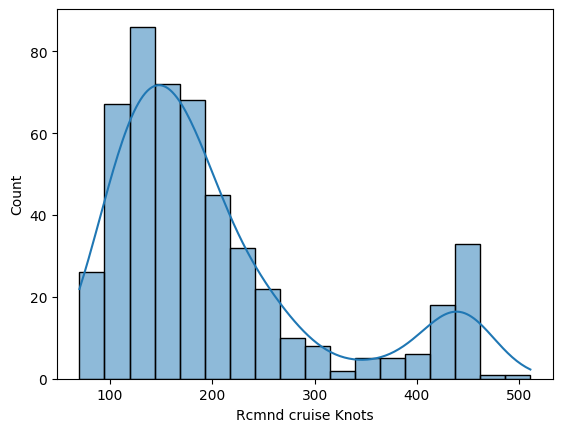

In [6]:
sns.histplot(df["Rcmnd cruise Knots"], kde=True)

<Axes: xlabel='Stall Knots dirty', ylabel='Count'>

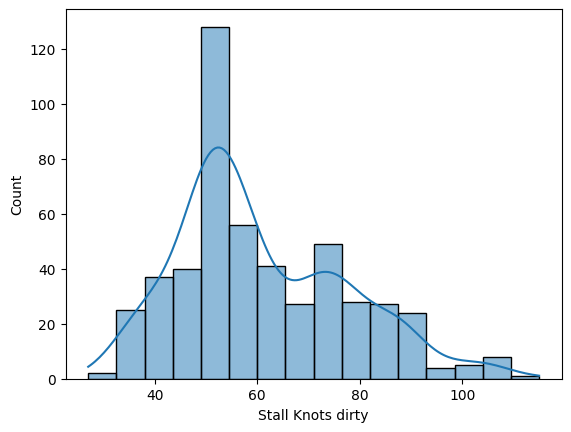

In [7]:
sns.histplot(df["Stall Knots dirty"],kde=True)

<Axes: xlabel='Eng out rate of climb', ylabel='Count'>

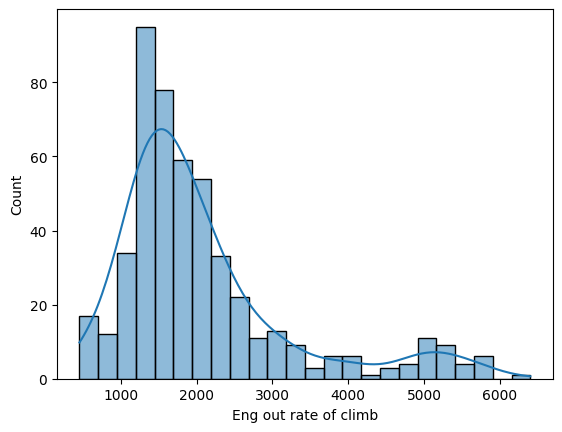

In [8]:
sns.histplot(df["Eng out rate of climb"],kde=True)

<Axes: xlabel='Takeoff over 50ft', ylabel='Count'>

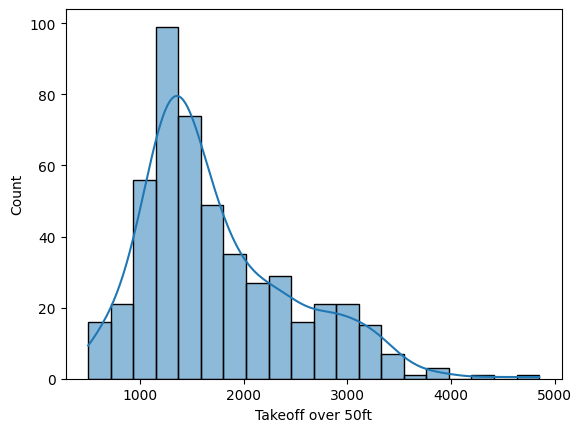

In [9]:
sns.histplot(df["Takeoff over 50ft"],kde=True)

## 4. Hedef Temizliği ve Eğitim-Test Bölünmesi (`train_test_split`)

### ⚠️ Veri Sızıntısı (Data Leakage) Düzeltmesi
- Önce hedef değişkeni (`Price`) eksik olan satırlar düşürülür.
- **Kritik kural:** Eksik veri doldurma (`median`/`mode`), One-Hot Encoding (`get_dummies`) ve ölçeklendirme (`StandardScaler`) istatistikleri **yalnızca eğitim setinden (`x_train`) öğrenilmeli**, ardından test setine (`x_test`) uygulanmalıdır. Bu nedenle `train_test_split` işlemi doldurma ve kodlama adımlarından **önce** yapılır.

In [10]:
# Hedef değişkeni eksik olan satırları çıkar
df = df[df["Price"].notnull()].copy()

y = df["Price"]
x = df.drop("Price", axis=1)

# Veri sızıntısını önlemek için split işlemini imputation ve encoding'den ÖNCE yap
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)
x_train = x_train.copy()
x_test = x_test.copy()


## 5. Sızıntısız Eksik Veri Doldurma (Imputation) ve Bug Düzeltmesi

**BUG FIX:** Orijinal kodda `Rcmnd cruise Knots` sütununda `.median()` parantez dışına yazılmıştı:
```python
# ❌ Eski hatalı kod (tüm sütunu tek bir skaler medyan değerine eşitliyordu)
df.loc[:,"Rcmnd cruise Knots"] = df["Rcmnd cruise Knots"].fillna(df["Rcmnd cruise Knots"]).median()
```
Aşağıda hem bu parantez hatası düzeltilmiş hem de tüm `median` / `mode` istatistikleri yalnızca `x_train` üzerinden hesaplanıp `x_train` ve `x_test` setlerine uygulanmıştır.

In [11]:
# Çarpık sayısal sütunlar: yalnızca x_train medyanı ile doldur
median_cols = [
    "Rcmnd cruise Knots",
    "Stall Knots dirty",
    "Eng out rate of climb",
    "Takeoff over 50ft",
]
for c in median_cols:
    med = x_train[c].median()
    x_train[c] = x_train[c].fillna(med)
    x_test[c] = x_test[c].fillna(med)

# Kategorik/metin sütunlar: yalnızca x_train modu ile doldur
mode_cols = [
    "Max speed Knots",
    "Range N.M.",
    "All eng rate of climb",
    "Empty weight lbs",
]
for c in mode_cols:
    mod = x_train[c].mode()[0]
    x_train[c] = x_train[c].fillna(mod)
    x_test[c] = x_test[c].fillna(mod)

print("x_train eksik toplam:", x_train.isnull().sum().sum())
print("x_test eksik toplam:", x_test.isnull().sum().sum())


x_train eksik toplam: 0
x_test eksik toplam: 0


## 6. Kategorik Kodlama (One-Hot Encoding) ve Ölçeklendirme (`StandardScaler`)
- `object` tipindeki sütunlar `x_train` ve `x_test` üzerinde ayrı ayrı `pd.get_dummies(..., drop_first=True)` ile kodlanır ve `x_test` sütunları `reindex(columns=x_train.columns, fill_value=0)` ile eğitim şemasına hizalanır.
- `StandardScaler` yalnızca `x_train` üzerine `fit_transform`, `x_test` üzerine ise `transform` edilir (orijinaldeki hatalı `scaler.fit([y_train])` satırı kaldırılmıştır).

In [12]:
col = x_train.select_dtypes(include="object").columns.tolist()
x_train = pd.get_dummies(x_train, columns=col, drop_first=True)
x_test = pd.get_dummies(x_test, columns=col, drop_first=True)
x_test = x_test.reindex(columns=x_train.columns, fill_value=0)

scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)


## 7. Model Eğitimi ve Performans Metrikleri
`LinearRegression` modeli ölçeklendirilmiş eğitim verisi üzerinde kurulur ve test seti üzerinde **R²**, **RMSE** ve **MAE** metrikleri hesaplanır.

In [13]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

lr = LinearRegression()
model = lr.fit(x_train_scaled, y_train)

y_pred = model.predict(x_test_scaled)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)
r2 = model.score(x_test_scaled, y_test)
print(f"R²:   {r2:.4f}")
print(f"RMSE: {rmse:,.2f}")
print(f"MAE:  {mae:,.2f}")


R²:   0.7257
RMSE: 505,871.19
MAE:  358,087.70


## 📝 Özet ve Değerlendirme (Holdout Doğrulama — %20 `train_test_split`)

> **Not:** Tüm metrikler `train_test_split(..., test_size=0.2, random_state=42)` ile ayrılan %20 holdout doğrulama seti üzerinde hesaplanmıştır.

| Model | Holdout R² | RMSE | MAE |
|---|---|---|---|
| LinearRegression (düzeltilmiş) | **0.7257** | **505,871.19** | **358,087.70** |

### Düzeltilen Gerçek Hatalar ve Skor Değişimi Notu
- Orijinal notebook'taki `0.8036` R² skorundan `0.7257`'ye değişim **yalnızca veri sızıntısının giderilmesine bağlanamaz**; aşağıdaki değişikliklerin tamamı birlikte uygulanmıştır (izole ablasyon yapılmamıştır):
  1. **`Rcmnd cruise Knots` `.median()` parantez hatası:** Önceki haliyle tüm sütun tek bir medyan sabitine çöküyordu; `fillna(med)` şeklinde düzeltildi.
  2. **Eksik veri ve encoding sızıntısı (Data Leakage):** `train_test_split` işlemi imputation ve `get_dummies` (`reindex`) öncesine alınarak medyan, mod ve sütun şeması yalnızca `x_train` üzerinden öğrenildi.
  3. **`StandardScaler` hatası:** Orijinaldeki `scaler.fit([y_train])` ve `df` üzerine yazma hataları kaldırıldı; `x_train_scaled` ve `x_test_scaled` tutarlı biçimde model eğitim ve tahmininde kullanıldı.
  4. **Eksik metrikler:** Tek başına `R²` yerine `RMSE` ve `MAE` eklendi.

### Geliştirme Önerileri
- Sayısal olmasına rağmen metin (`object`) olarak okunan `HP or lbs thr ea engine`, `Max speed Knots`, `Empty weight lbs`, `Range N.M.` gibi sütunları temizleyip sayısala çevirmek ve `Model Name` gibi benzersiz tanımlayıcı sütunu çıkarmak genelleme performansını belirgin şekilde artıracaktır.